In [ ]:
# Mount Drive & install
from google.colab import drive
drive.mount('/content/drive')

import os
WAV_FLAT = "/content/MOSEI_wav_flat"
MP4_FLAT = "/content/MOSEI_faces_flat"

# If flat dirs don't exist yet (fresh runtime), unzip the source archives
if not os.path.exists(WAV_FLAT) or len(os.listdir(WAV_FLAT)) == 0:
    !unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw_Wav.zip" -d /content/MOSEI_wav
    !find /content/MOSEI_wav -name "._*" -delete
    !rm -rf /content/MOSEI_wav/__MACOSX
    import shutil
    SRC_DIR  = "/content/MOSEI_wav/Raw_Wav"
    os.makedirs(WAV_FLAT, exist_ok=True)
    for video_id in os.listdir(SRC_DIR):
        video_path = os.path.join(SRC_DIR, video_id)
        if not os.path.isdir(video_path):
            continue
        for fname in os.listdir(video_path):
            if not fname.endswith(".wav"):
                continue
            clip_id = fname.replace(".wav", "")
            shutil.copy2(os.path.join(video_path, fname),
                         os.path.join(WAV_FLAT, f"{video_id}__{clip_id}.wav"))
    print(f"Flattened {len(os.listdir(WAV_FLAT))} wav files")

if not os.path.exists(MP4_FLAT) or len(os.listdir(MP4_FLAT)) == 0:
    !unzip -q "/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/Raw-Cropped-FULL.zip" -d /content/MOSEI_faces
    !find /content/MOSEI_faces -name "._*" -delete
    !rm -rf /content/MOSEI_faces/__MACOSX
    import shutil
    SRC_DIR  = "/content/MOSEI_faces/Raw-Cropped-FULL"
    os.makedirs(MP4_FLAT, exist_ok=True)
    for video_id in os.listdir(SRC_DIR):
        video_path = os.path.join(SRC_DIR, video_id)
        if not os.path.isdir(video_path):
            continue
        for fname in os.listdir(video_path):
            if not fname.endswith(".mp4"):
                continue
            shutil.copy2(os.path.join(video_path, fname),
                         os.path.join(MP4_FLAT, f"{video_id}__{fname}"))
    print(f"Flattened {len(os.listdir(MP4_FLAT))} mp4 files")

# Copy label CSV locally
import shutil
CSV_DST = "/content/label_FULLY_PRUNED.csv"
if not os.path.exists(CSV_DST):
    shutil.copy2("/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_FULLY_PRUNED.csv", CSV_DST)

!pip install -q einops decord
!pip install -q timm==0.4.12

if not os.path.exists("/content/MAE-DFER"):
    !git clone https://github.com/sunlicai/MAE-DFER.git /content/MAE-DFER

import sys
sys.path.insert(0, '/content/MAE-DFER')
import modeling_finetune
from timm.models import create_model


Mounted at /content/drive
Flattened 22856 wav files
Flattened 22856 mp4 files
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 97.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 9.1 MB/s eta 0:00:00
Cloning into '/content/MAE-DFER'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 259 (delta 50), reused 17 (delta 17), pack-reused 181 (from 1)
Receiving objects: 100% (259/259), 16.52 MiB | 51.72 MiB/s, done.
Resolving deltas: 100% (98/98), done.


In [ ]:
# Imports, hyperparams, helpers
import os, gc, random, shutil, copy, contextlib, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import soundfile as sf
import cv2
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    HubertModel, AutoModel, AutoTokenizer, AutoFeatureExtractor,
    get_cosine_schedule_with_warmup,
)
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr

# Paths
ENRICHED_CSV     = "/content/label_FULLY_PRUNED.csv"
FLAT_WAV_DIR     = "/content/MOSEI_wav_flat"
FLAT_MP4_DIR     = "/content/MOSEI_faces_flat"
OUTPUT_DIR       = "/content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v6"
os.makedirs(OUTPUT_DIR, exist_ok=True)

HUBERT_WEIGHTS   = "/content/drive/Shareddrives/AI Capstone/Audio Models/hubert-mosei-multitask-llrd/best_model.pt"
DEBERTA_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model.pt"
MAEDFER_WEIGHTS  = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Checkpoints (Final Model)/best_model.pt"
MAEDFER_PRETRAIN = "/content/drive/Shareddrives/AI Capstone/Video Models/MAE-DFER/Pretrained/checkpoint-49.pth"

HUBERT_CHECKPOINT  = "facebook/hubert-base-ls960"
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-base"

HUBERT_DIM  = 768
DEBERTA_DIM = 768
MAEDFER_DIM = 512

# Data hyperparams
NUM_FRAMES    = 16
IMAGE_SIZE    = 160
VIDEO_MEAN    = [0.5, 0.5, 0.5]
VIDEO_STD     = [0.5, 0.5, 0.5]
SAMPLE_RATE   = 16_000
MAX_AUDIO_LEN = int(8.0 * SAMPLE_RATE)
MAX_TEXT_LEN  = 128

# Training hyperparams
BATCH_SIZE       = 16
GRAD_ACCUM       = 2
MAX_EPOCHS       = 200
PATIENCE         = 15
LR_FUSION        = 5e-5
WD               = 0.01
WARMUP_RATIO     = 0.05
SEED             = 42
D_MODEL          = 256
NUM_HEADS        = 8
DROPOUT_PROB     = 0.35
CCC_ALPHA        = 0.6
LABEL_SMOOTHING  = 0.05
SENTIMENT_WEIGHT = 1.0
EMOTION_WEIGHT   = 1.0
POOL_LEN         = 16

# aux loss weight & mixture init
AUX_WEIGHT = 0.2  # how much aux unimodal losses contribute vs main combined loss

# Logits-before-softmax init for the 4-way mixture [text, audio, video, fuse].
# Softmax of these gives roughly the priors below - text dominates sentiment,
# audio dominates emotion, video starts low so it has to earn its way in.
#   sent: softmax([0.0, -1.3, -2.4, -0.8]) ≈ [0.55, 0.15, 0.05, 0.25]
#   emot: softmax([-1.3, 0.0, -2.4, -0.8]) ≈ [0.15, 0.55, 0.05, 0.25]
MIXTURE_INIT_SENT = [ 0.0, -1.3, -2.4, -0.8]
MIXTURE_INIT_EMOT = [-1.3,  0.0, -2.4, -0.8]

EMOTION_COLS      = ["happy", "sad", "anger", "fear", "disgust", "surprise"]
EMOTION_THRESHOLD = 0.5

# Carry over best avg CCC from v5 - only save if v6 actually beats it
V5_BEST_AVG_CCC = 0.4101

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device: cuda
GPU  : NVIDIA A100-SXM4-40GB
VRAM : 42.4 GB


In [ ]:
# Metrics & loss functions
def ccc_np(y_true, y_pred):
    y_true = np.array(y_true, dtype=np.float64)
    y_pred = np.array(y_pred, dtype=np.float64)
    if np.std(y_true) < 1e-8 or np.std(y_pred) < 1e-8:
        return 0.0, 0.0
    rho, _    = pearsonr(y_true, y_pred)
    std_true  = np.std(y_true)
    std_pred  = np.std(y_pred)
    mean_true = np.mean(y_true)
    mean_pred = np.mean(y_pred)
    num       = 2.0 * rho * std_true * std_pred
    den       = std_true**2 + std_pred**2 + (mean_true - mean_pred)**2
    return float(num / den if den > 1e-8 else 0.0), float(rho)


def ccc_loss_single(pred, target):
    mean_p = pred.mean()
    mean_t = target.mean()
    cov    = ((pred - mean_p) * (target - mean_t)).mean()
    std_p  = pred.std()
    std_t  = target.std()
    if std_t < 1e-3 or std_p < 1e-3:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    denom = std_p**2 + std_t**2 + (mean_p - mean_t)**2 + 1e-4
    return 1.0 - (2.0 * cov) / denom


def sentiment_loss(pred, target, alpha=CCC_ALPHA):
    ccc = ccc_loss_single(pred, target)
    mse = F.mse_loss(pred, target)
    return alpha * ccc + (1.0 - alpha) * mse


def emotion_loss(pred, target, emotion_weights, alpha=CCC_ALPHA, smoothing=LABEL_SMOOTHING):
    target_smooth = target * (1.0 - smoothing) + 0.5 * smoothing
    ccc = torch.stack([
        ccc_loss_single(pred[:, i], target[:, i]) * emotion_weights[i]
        for i in range(pred.shape[1])
    ]).mean()
    w = emotion_weights.unsqueeze(0).expand_as(pred)
    bce = F.binary_cross_entropy(pred.clamp(1e-6, 1.0 - 1e-6),
                                  target_smooth.clamp(0, 1), weight=w)
    return alpha * ccc + (1.0 - alpha) * bce


def sentiment_to_class(score):
    if score > 0:   return "Positive"
    elif score < 0: return "Negative"
    else:           return "Neutral"


def emotion_vector_to_labels(pred_vector, threshold=EMOTION_THRESHOLD):
    dominant = EMOTION_COLS[int(np.argmax(pred_vector))]
    present  = [EMOTION_COLS[i] for i, v in enumerate(pred_vector) if v >= threshold]
    return dominant, present


In [ ]:
# Load labels & build splits
df = pd.read_csv(ENRICHED_CSV)
df["video_id"] = df["video_id"].astype(str)
df["clip_id"]  = df["clip_id"].astype(str)
print(f"Loaded {len(df)} rows")

df["wav_path"] = df.apply(lambda r: f"{FLAT_WAV_DIR}/{r['video_id']}__{r['clip_id']}.wav", axis=1)
df["mp4_path"] = df.apply(lambda r: f"{FLAT_MP4_DIR}/{r['video_id']}__{r['clip_id']}.mp4", axis=1)

before = len(df)
df = df[df["wav_path"].apply(os.path.exists) & df["mp4_path"].apply(os.path.exists)].copy()
print(f"Dropped {before - len(df)} missing files  |  Remaining: {len(df)}")

df["sentiment_norm"] = df["sentiment"].clip(-3, 3) / 3.0
for col in EMOTION_COLS:
    df[col] = df[col].clip(0, 1)

train_df = df[df["mode"] == "train"].reset_index(drop=True)
val_df   = df[df["mode"] == "valid"].reset_index(drop=True)
test_df  = df[df["mode"] == "test"].reset_index(drop=True)
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

# Emotion class weights - inverse frequency, clipped, normalised to mean=1
emotion_means  = train_df[EMOTION_COLS].mean().values
raw_weights    = 1.0 / (emotion_means + 0.05)
raw_weights    = np.clip(raw_weights, None, 5.0)
raw_weights    = raw_weights / raw_weights.mean()
# EMOTION_WEIGHTS = torch.tensor(raw_weights, dtype=torch.float32).to(device)
EMOTION_WEIGHTS = torch.ones(6, dtype=torch.float32).to(device)
print("\nEmotion loss weights:")
for col, w in zip(EMOTION_COLS, raw_weights):
    print(f"  {col:<10}: {w:.3f}")


Loaded 19970 rows
Dropped 0 missing files  |  Remaining: 19970
Train: 14179  |  Val: 1671  |  Test: 4120

Emotion loss weights:
  happy     : 0.520
  sad       : 1.096
  anger     : 1.096
  fear      : 1.096
  disgust   : 1.096
  surprise  : 1.096


In [ ]:
# Dataset & dataloaders
audio_feature_extractor = AutoFeatureExtractor.from_pretrained(HUBERT_CHECKPOINT)
text_tokenizer          = AutoTokenizer.from_pretrained(DEBERTA_CHECKPOINT)

video_mean = np.array(VIDEO_MEAN, dtype=np.float32)
video_std  = np.array(VIDEO_STD,  dtype=np.float32)


def load_video_frames(mp4_path, num_frames=NUM_FRAMES, image_size=IMAGE_SIZE):
    cap   = cv2.VideoCapture(mp4_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release()
        return torch.zeros(3, num_frames, image_size, image_size)
    indices = np.linspace(0, total - 1, num_frames, dtype=int)
    frames  = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (image_size, image_size))
        else:
            frame = np.zeros((image_size, image_size, 3), dtype=np.uint8)
        frame = frame.astype(np.float32) / 255.0
        frame = (frame - video_mean) / video_std
        frames.append(frame)
    cap.release()
    video = np.stack(frames, axis=0)
    return torch.from_numpy(video).permute(3, 0, 1, 2)


class MOSEIFusionDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            audio, _ = sf.read(row["wav_path"], dtype="float32")
        except Exception:
            audio = np.zeros(MAX_AUDIO_LEN, dtype=np.float32)
        if len(audio) > MAX_AUDIO_LEN:
            audio = audio[:MAX_AUDIO_LEN]
        text  = str(row["text"]) if pd.notna(row.get("text", "")) else ""
        video = load_video_frames(row["mp4_path"])
        sentiment = float(row["sentiment_norm"])
        emotions  = [float(row[c]) for c in EMOTION_COLS]
        return audio, text, video, sentiment, emotions


def collate_fn(batch):
    audios, texts, videos, sentiments, emotions = zip(*batch)
    audio_inputs = audio_feature_extractor(
        list(audios), sampling_rate=SAMPLE_RATE,
        max_length=MAX_AUDIO_LEN, truncation=True,
        padding="max_length", return_tensors="pt",
    )
    text_inputs = text_tokenizer(
        list(texts), padding=True, truncation=True,
        max_length=MAX_TEXT_LEN, return_tensors="pt",
    )
    video_tensor = torch.stack(list(videos))
    return {
        "input_values":     audio_inputs["input_values"],
        "input_ids":        text_inputs["input_ids"],
        "attention_mask":   text_inputs["attention_mask"],
        "pixel_values":     video_tensor,
        "sentiment_labels": torch.tensor(sentiments, dtype=torch.float32),
        "emotion_labels":   torch.tensor(emotions,   dtype=torch.float32),
    }


train_loader = DataLoader(MOSEIFusionDataset(train_df), batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=8, collate_fn=collate_fn,
                          pin_memory=True)
val_loader   = DataLoader(MOSEIFusionDataset(val_df),   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn,
                          pin_memory=True)
test_loader  = DataLoader(MOSEIFusionDataset(test_df),  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=8, collate_fn=collate_fn,
                          pin_memory=True)
print(f"Batches - train: {len(train_loader)}  val: {len(val_loader)}  test: {len(test_loader)}")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/213 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Batches — train: 887  val: 105  test: 258


In [ ]:
# Load backbones - ALL FROZEN in v6
# Why all frozen: v5 attempt to fine-tune last 2 layers hit an AdamW NaN bug
# that we couldn't get past. Late mixture is the better lever anyway -
# unimodal features are already strong (text 0.69 SCCC, audio 0.30 ECCC).

print("Loading HuBERT…")
hubert = HubertModel.from_pretrained(HUBERT_CHECKPOINT)
state  = torch.load(HUBERT_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]
hubert_state = {k[len("hubert."):]: v for k, v in state.items() if k.startswith("hubert.")}
if hubert_state:
    missing, unexpected = hubert.load_state_dict(hubert_state, strict=False)
    print(f"  HuBERT load: {len(missing)} missing, {len(unexpected)} unexpected")
for p in hubert.parameters():
    p.requires_grad = False
hubert.feature_extractor._requires_grad = False
hubert.config.apply_spec_augment = False
hubert = hubert.to(device).eval()

print("Loading DeBERTa…")
deberta = AutoModel.from_pretrained(DEBERTA_CHECKPOINT)
state   = torch.load(DEBERTA_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]
deberta_state = {k[len("encoder."):]: v for k, v in state.items() if k.startswith("encoder.")}
missing, unexpected = deberta.load_state_dict(deberta_state, strict=False)
print(f"  DeBERTa load: {len(missing)} missing, {len(unexpected)} unexpected from {len(deberta_state)} filtered keys")
for p in deberta.parameters():
    p.requires_grad = False
deberta = deberta.to(device).eval()

print("Loading MAE-DFER…")

class MAEDFERBackbone(nn.Module):
    def __init__(self, pretrain_ckpt):
        super().__init__()
        self.backbone = create_model(
            'vit_base_dim512_no_depth_patch16_160',
            pretrained=False, num_classes=7, all_frames=NUM_FRAMES,
            tubelet_size=2, use_mean_pooling=True,
            attn_type='local_global', lg_region_size=(2, 5, 10),
            lg_first_attn_type='self', lg_third_attn_type='cross',
            lg_attn_param_sharing_first_third=False,
            lg_attn_param_sharing_all=False,
            lg_classify_token_type='org',
            lg_no_second=False, lg_no_third=False,
            drop_path_rate=0.1, init_values=0.0,
        )
        self.backbone.head = nn.Identity()
        ckpt       = torch.load(pretrain_ckpt, map_location='cpu', weights_only=False)
        state_dict = ckpt['model'] if 'model' in ckpt else ckpt
        self.backbone.load_state_dict(state_dict, strict=False)

    def forward(self, x):
        return self.backbone(x)

maedfer  = MAEDFERBackbone(MAEDFER_PRETRAIN)
ft_state = torch.load(MAEDFER_WEIGHTS, map_location=device, weights_only=False)
if "model_state_dict" in ft_state:
    ft_state = ft_state["model_state_dict"]
backbone_state = {k.replace("backbone.", ""): v for k, v in ft_state.items()
                  if not k.startswith("head.")}
maedfer.backbone.load_state_dict(backbone_state, strict=False)
for p in maedfer.parameters():
    p.requires_grad = False
maedfer = maedfer.to(device).eval()

# Verify all backbones are clean
for name, m in [("hubert", hubert), ("deberta", deberta), ("maedfer", maedfer)]:
    bad = sum(1 for _, p in m.named_parameters() if not torch.isfinite(p).all())
    print(f"  {name}: non-finite params = {bad}")

if device.type == "cuda":
    print(f"\nVRAM after backbones: {torch.cuda.memory_allocated(device) / 1e9:.2f} GB")


Loading HuBERT…


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

  HuBERT load: 0 missing, 0 unexpected
Loading DeBERTa…


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

  DeBERTa load: 0 missing, 0 unexpected from 198 filtered keys
Loading MAE-DFER…
==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
  hubert: non-finite params = 0
  deberta: non-finite params = 0
  maedfer: non-finite params = 0

VRAM after backbones: 2.42 GB


In [ ]:
# v6 Fusion architecture

class SequencePool(nn.Module):
    def __init__(self, d_model, pool_len=POOL_LEN):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(pool_len, d_model) * 0.02)
        self.attn    = nn.MultiheadAttention(d_model, num_heads=4,
                                              dropout=0.1, batch_first=True)
        self.norm    = nn.LayerNorm(d_model)

    def forward(self, x):
        B    = x.size(0)
        q    = self.queries.unsqueeze(0).expand(B, -1, -1)
        out, _ = self.attn(q, x, x)
        return self.norm(out)


class TaskFusionPath(nn.Module):
    def __init__(self, d_model, num_heads, out_dim, dropout=0.2):
        super().__init__()
        self.cls_query  = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.cross_attn = nn.MultiheadAttention(d_model, num_heads,
                                                 dropout=0.1, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, out_dim),
        )

    def forward(self, t_pool, a_pool, v_pool):
        B   = t_pool.size(0)
        kv  = torch.cat([t_pool, a_pool, v_pool], dim=1)
        cls = self.cls_query.expand(B, -1, -1)
        attended, _ = self.cross_attn(cls, kv, kv)
        cls_out     = self.norm1(cls + attended)
        ffn_out     = self.ffn(cls_out)
        cls_out     = self.norm2(cls_out + ffn_out)
        return self.head(cls_out.squeeze(1))


class LateMixtureFusionV6(nn.Module):
    """
    Late mixture fusion with auxiliary unimodal heads.

    Pipeline:
      1. Project each modality to d_model, sequence-pool to POOL_LEN tokens.
      2. Aux heads: mean-pool over sequence dim, then 1 linear layer per task.
         Aux heads always see their modality (no dropout) - they regularize
         the projection layers and provide independent unimodal predictions.
      3. Fusion paths: modality dropout applied to pooled sequences, then
         cross-attention over the concatenated stream for each task.
      4. Final prediction: softmax-weighted mixture of [text, audio, video, fuse]
         predictions, with separate learnable mixture weights per task.
      5. Loss: main_loss(combined) + AUX_WEIGHT * mean(aux losses).
    """
    def __init__(self, d_model=D_MODEL, num_heads=NUM_HEADS, dropout=DROPOUT_PROB):
        super().__init__()
        self.dropout_prob = 0.20

        # Projections
        self.text_proj  = nn.Linear(DEBERTA_DIM, d_model)
        self.audio_proj = nn.Linear(HUBERT_DIM,  d_model)
        self.video_proj = nn.Linear(MAEDFER_DIM, d_model)

        # Sequence pools
        self.text_pool  = SequencePool(d_model, POOL_LEN)
        self.audio_pool = SequencePool(d_model, POOL_LEN)
        self.video_norm = nn.LayerNorm(d_model)

        # Auxiliary unimodal heads - 1 linear layer per modality per task
        self.text_aux_sent  = nn.Linear(d_model, 1)
        self.audio_aux_sent = nn.Linear(d_model, 1)
        self.video_aux_sent = nn.Linear(d_model, 1)
        self.text_aux_emot  = nn.Linear(d_model, 6)
        self.audio_aux_emot = nn.Linear(d_model, 6)
        self.video_aux_emot = nn.Linear(d_model, 6)

        # Fusion paths (one per task, same architecture as v5)
        self.sent_path = TaskFusionPath(d_model, num_heads, out_dim=1, dropout=dropout)
        self.emot_path = TaskFusionPath(d_model, num_heads, out_dim=6, dropout=dropout)

        # 4-way mixture weights: [text, audio, video, fuse] per task
        self.sent_weights = nn.Parameter(torch.tensor(MIXTURE_INIT_SENT, dtype=torch.float32))
        self.emot_weights = nn.Parameter(torch.tensor(MIXTURE_INIT_EMOT, dtype=torch.float32))

    def _modality_dropout(self, t, a, v):
        """Zero a modality's entire pooled sequence with probability dropout_prob."""
        if not self.training:
            return t, a, v
        dev = t.device
        m_t = (torch.rand(1) > self.dropout_prob).float().to(dev)
        m_a = (torch.rand(1) > self.dropout_prob).float().to(dev)
        m_v = (torch.rand(1) > self.dropout_prob).float().to(dev)
        if (m_t + m_a + m_v).item() == 0:
            idx = torch.randint(0, 3, (1,)).item()
            if   idx == 0: m_t = torch.ones(1).to(dev)
            elif idx == 1: m_a = torch.ones(1).to(dev)
            else:          m_v = torch.ones(1).to(dev)
        scale = 3.0 / (m_t + m_a + m_v)
        return (t * m_t * scale, a * m_a * scale, v * m_v * scale)

    def forward(self, text_feat, video_feat, audio_feat,
                sentiment_labels=None, emotion_labels=None,
                emotion_weights=None):

        # Project & pool
        t = self.text_proj(text_feat)
        a = self.audio_proj(audio_feat)
        v = self.video_proj(
            video_feat.unsqueeze(1) if video_feat.dim() == 2 else video_feat
        )
        t_pool = self.text_pool(t)                              # (B, POOL_LEN, d_model)
        a_pool = self.audio_pool(a)                             # (B, POOL_LEN, d_model)
        v_pool = self.video_norm(v).expand(-1, POOL_LEN, -1)    # (B, POOL_LEN, d_model)

        # Aux head inputs - mean over sequence dim. NOT subject to modality dropout.
        t_vec = t_pool.mean(dim=1)   # (B, d_model)
        a_vec = a_pool.mean(dim=1)
        v_vec = v_pool.mean(dim=1)

        # Aux predictions (always active, not affected by modality dropout)
        sent_t = torch.tanh(self.text_aux_sent(t_vec).squeeze(-1))     # (B,)
        sent_a = torch.tanh(self.audio_aux_sent(a_vec).squeeze(-1))
        sent_v = torch.tanh(self.video_aux_sent(v_vec).squeeze(-1))
        emot_t = torch.sigmoid(self.text_aux_emot(t_vec))              # (B, 6)
        emot_a = torch.sigmoid(self.audio_aux_emot(a_vec))
        emot_v = torch.sigmoid(self.video_aux_emot(v_vec))

        # Fusion path: modality dropout applied on the way in
        t_pool_d, a_pool_d, v_pool_d = self._modality_dropout(t_pool, a_pool, v_pool)
        sent_f = torch.tanh(self.sent_path(t_pool_d, a_pool_d, v_pool_d).squeeze(-1))
        emot_f = torch.sigmoid(self.emot_path(t_pool_d, a_pool_d, v_pool_d))

        # 4-way mixture combination
        w_sent = F.softmax(self.sent_weights, dim=0)   # (4,)
        w_emot = F.softmax(self.emot_weights, dim=0)   # (4,)

        sent_pred = (w_sent[0] * sent_t + w_sent[1] * sent_a +
                     w_sent[2] * sent_v + w_sent[3] * sent_f)
        emot_pred = (w_emot[0] * emot_t + w_emot[1] * emot_a +
                     w_emot[2] * emot_v + w_emot[3] * emot_f)

        # Bundle per-modality predictions for diagnostics
        aux_preds = {
            "sent_text":  sent_t, "sent_audio": sent_a,
            "sent_video": sent_v, "sent_fuse":  sent_f,
            "emot_text":  emot_t, "emot_audio": emot_a,
            "emot_video": emot_v, "emot_fuse":  emot_f,
            "w_sent": w_sent.detach(),
            "w_emot": w_emot.detach(),
        }

        loss = None
        if sentiment_labels is not None and emotion_labels is not None:
            ew = emotion_weights if emotion_weights is not None \
                 else torch.ones(6, device=emot_pred.device)

            # Main loss on the combined predictions
            s_main = sentiment_loss(sent_pred, sentiment_labels)
            e_main = emotion_loss(emot_pred, emotion_labels, ew)

            # Aux losses on each unimodal stream + the fusion path output
            s_aux = (sentiment_loss(sent_t, sentiment_labels) +
                     sentiment_loss(sent_a, sentiment_labels) +
                     sentiment_loss(sent_v, sentiment_labels) +
                     sentiment_loss(sent_f, sentiment_labels)) / 4.0
            e_aux = (emotion_loss(emot_t, emotion_labels, ew) +
                     emotion_loss(emot_a, emotion_labels, ew) +
                     emotion_loss(emot_v, emotion_labels, ew) +
                     emotion_loss(emot_f, emotion_labels, ew)) / 4.0

            loss = (SENTIMENT_WEIGHT * s_main + EMOTION_WEIGHT * e_main +
                    AUX_WEIGHT * (SENTIMENT_WEIGHT * s_aux + EMOTION_WEIGHT * e_aux))

        return loss, sent_pred, emot_pred, aux_preds


fusion = LateMixtureFusionV6().to(device)
n_params = sum(p.numel() for p in fusion.parameters() if p.requires_grad)
print(f"v6 trainable params: {n_params:,}")

# Show init mixture weights
with torch.no_grad():
    w_s = F.softmax(fusion.sent_weights, dim=0).cpu().numpy()
    w_e = F.softmax(fusion.emot_weights, dim=0).cpu().numpy()
print(f"Init sent weights  [text, audio, video, fuse]: {w_s.round(3)}")
print(f"Init emot weights  [text, audio, video, fuse]: {w_e.round(3)}")


v6 trainable params: 2,187,940
Init sent weights  [text, audio, video, fuse]: [0.552 0.15  0.05  0.248]
Init emot weights  [text, audio, video, fuse]: [0.15  0.552 0.05  0.248]


In [ ]:
# Optimizer
RESUME_CKPT_V6 = f"{OUTPUT_DIR}/resume_checkpoint_v6.pt"

# Single param group - backbones are frozen
optimizer = AdamW(
    [{"params": fusion.parameters(), "lr": LR_FUSION, "weight_decay": WD}],
)

total_steps = (len(train_loader) // GRAD_ACCUM) * MAX_EPOCHS
scheduler   = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps,
)

history = {
    "train_loss": [], "val_loss": [],
    "sent_ccc": [], "sent_plcc": [], "sent_mae": [],
    "mean_emot_ccc": [], "emot_mae": [],
    "w_sent": [], "w_emot": [],
}

best_avg_ccc   = V5_BEST_AVG_CCC
best_epoch     = 0
patience_count = 0
start_epoch    = 1
best_fusion_state = copy.deepcopy(fusion.state_dict())

if os.path.exists(RESUME_CKPT_V6):
    try:
        print(f"v6 resume checkpoint found - continuing…")
        ckpt = torch.load(RESUME_CKPT_V6, map_location=device, weights_only=False)
        fusion.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        best_avg_ccc      = ckpt["best_avg_ccc"]
        best_epoch        = ckpt["best_epoch"]
        patience_count    = ckpt["patience_count"]
        history           = ckpt["history"]
        best_fusion_state = ckpt["best_model_state_dict"]
        start_epoch       = ckpt["epoch"] + 1
        print(f"  Resumed from epoch {ckpt['epoch']}  |  best avg CCC: {best_avg_ccc:.4f}")
    except (RuntimeError, KeyError) as e:
        print(f"  ⚠ Checkpoint corrupt or incompatible ({e}) - starting fresh")
        os.remove(RESUME_CKPT_V6)
else:
    print("No v6 checkpoint - fresh start")

print(f"\nTrainable fusion params: {sum(p.numel() for p in fusion.parameters() if p.requires_grad):,}")
print(f"LR: {LR_FUSION}  |  WD: {WD}")
print(f"Start epoch: {start_epoch}  |  beat avg CCC: {best_avg_ccc:.4f}")


No v6 checkpoint — fresh start

Trainable fusion params: 2,187,940
LR: 5e-05  |  WD: 0.01
Start epoch: 1  |  beat avg CCC: 0.4101


In [ ]:
# Feature extraction (backbones in no_grad always since frozen)
def extract_features(batch):
    with torch.no_grad():
        input_values   = batch["input_values"].to(device)
        input_ids      = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        pixel_values   = batch["pixel_values"].to(device)

        audio_feat = hubert(input_values=input_values).last_hidden_state.float()
        text_feat  = deberta(input_ids=input_ids,
                              attention_mask=attention_mask).last_hidden_state.float()
        video_feat = maedfer(pixel_values)

    return text_feat, video_feat, audio_feat


In [ ]:
# Evaluate
def evaluate(loader, return_per_modality=False):
    fusion.eval()

    all_sent_pred, all_sent_true = [], []
    all_emot_pred, all_emot_true = [], []
    total_loss = 0.0

    # Per-modality prediction accumulators (for diagnostic eval at end)
    per_mod_sent = {k: [] for k in ["text", "audio", "video", "fuse"]}
    per_mod_emot = {k: [] for k in ["text", "audio", "video", "fuse"]}
    last_w_sent, last_w_emot = None, None

    with torch.no_grad():
        for batch in loader:
            text_feat, video_feat, audio_feat = extract_features(batch)
            slbl = batch["sentiment_labels"].to(device)
            elbl = batch["emotion_labels"].to(device)
            loss, sent_pred, emot_pred, aux = fusion(
                text_feat, video_feat, audio_feat, slbl, elbl,
                emotion_weights=EMOTION_WEIGHTS,
            )
            total_loss += loss.item()
            all_sent_pred.extend((sent_pred.cpu().numpy() * 3).tolist())
            all_sent_true.extend((slbl.cpu().numpy()      * 3).tolist())
            all_emot_pred.extend(emot_pred.cpu().numpy().tolist())
            all_emot_true.extend(elbl.cpu().numpy().tolist())

            if return_per_modality:
                for src_key, dst_key in [("text", "sent_text"), ("audio", "sent_audio"),
                                          ("video", "sent_video"), ("fuse", "sent_fuse")]:
                    per_mod_sent[src_key].extend((aux[dst_key].cpu().numpy() * 3).tolist())
                for src_key, dst_key in [("text", "emot_text"), ("audio", "emot_audio"),
                                          ("video", "emot_video"), ("fuse", "emot_fuse")]:
                    per_mod_emot[src_key].extend(aux[dst_key].cpu().numpy().tolist())

            last_w_sent = aux["w_sent"].cpu().numpy()
            last_w_emot = aux["w_emot"].cpu().numpy()

    avg_loss        = total_loss / len(loader)
    sent_ccc_val, sent_plcc = ccc_np(all_sent_true, all_sent_pred)
    sent_mae                = mean_absolute_error(all_sent_true, all_sent_pred)
    all_emot_pred           = np.array(all_emot_pred)
    all_emot_true           = np.array(all_emot_true)
    emot_ccc_scores         = [ccc_np(all_emot_true[:, i], all_emot_pred[:, i])[0]
                                for i in range(len(EMOTION_COLS))]
    mean_emot_ccc           = float(np.mean(emot_ccc_scores))
    emot_mae                = mean_absolute_error(all_emot_true.flatten(),
                                                    all_emot_pred.flatten())

    result = {
        "loss": avg_loss,
        "sent_ccc": sent_ccc_val, "sent_plcc": sent_plcc, "sent_mae": sent_mae,
        "emot_ccc_scores": emot_ccc_scores, "mean_emot_ccc": mean_emot_ccc,
        "emot_mae": emot_mae,
        "sent_pred": all_sent_pred, "sent_true": all_sent_true,
        "emot_pred": all_emot_pred, "emot_true": all_emot_true,
        "w_sent": last_w_sent, "w_emot": last_w_emot,
    }
    if return_per_modality:
        result["per_mod_sent"] = per_mod_sent
        result["per_mod_emot"] = per_mod_emot
    return result


In [ ]:
# Sanity check
gc.collect(); torch.cuda.empty_cache()
print(f"VRAM before sanity check: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

batch = next(iter(train_loader))
text_feat, video_feat, audio_feat = extract_features(batch)
print(f"text_feat : {text_feat.shape}  range=[{text_feat.min().item():.2f}, {text_feat.max().item():.2f}]")
print(f"audio_feat: {audio_feat.shape}  range=[{audio_feat.min().item():.2f}, {audio_feat.max().item():.2f}]")
print(f"video_feat: {video_feat.shape}  range=[{video_feat.min().item():.2f}, {video_feat.max().item():.2f}]")

fusion.train()
loss, sp, ep, aux = fusion(
    text_feat, video_feat, audio_feat,
    batch["sentiment_labels"].to(device),
    batch["emotion_labels"].to(device),
    emotion_weights=EMOTION_WEIGHTS,
)
print(f"\nloss={loss.item():.4f}  sent_pred={sp.shape}  emot_pred={ep.shape}")
print(f"sent components: text={aux['sent_text'].mean().item():+.3f}  "
      f"audio={aux['sent_audio'].mean().item():+.3f}  "
      f"video={aux['sent_video'].mean().item():+.3f}  "
      f"fuse={aux['sent_fuse'].mean().item():+.3f}")
print(f"w_sent: {aux['w_sent'].cpu().numpy().round(3)}")
print(f"w_emot: {aux['w_emot'].cpu().numpy().round(3)}")

(loss / GRAD_ACCUM).backward()
optimizer.zero_grad()
print(f"\n✓ Sanity check passed  |  VRAM: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
gc.collect(); torch.cuda.empty_cache()


VRAM before sanity check: 2.44 GB
text_feat : torch.Size([16, 83, 768])  range=[-9.86, 14.91]
audio_feat: torch.Size([16, 399, 768])  range=[-8.01, 6.90]
video_feat: torch.Size([16, 512])  range=[-3.20, 3.63]

loss=2.0393  sent_pred=torch.Size([16])  emot_pred=torch.Size([16, 6])
sent components: text=+0.309  audio=-0.506  video=+0.828  fuse=+0.079
w_sent: [0.552 0.15  0.05  0.248]
w_emot: [0.15  0.552 0.05  0.248]

✓ Sanity check passed  |  VRAM: 2.48 GB


In [ ]:
# Training loop
print(f"\n{'Ep':>3} {'TrLoss':>8} {'VlLoss':>8} "
      f"{'SCCC':>8} {'SPLCC':>8} {'SMAE':>8} {'ECCC':>8} {'P':>4}")
print("─" * 70)

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    fusion.train()
    tr_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(train_loader):
        text_feat, video_feat, audio_feat = extract_features(batch)
        slbl = batch["sentiment_labels"].to(device)
        elbl = batch["emotion_labels"].to(device)

        # Quick input sanity (cheap, catches dataloader regressions early)
        if not torch.isfinite(text_feat).all():
            print(f"  ✗ text_feat non-finite at step {step}"); optimizer.zero_grad(); continue
        if not torch.isfinite(audio_feat).all():
            print(f"  ✗ audio_feat non-finite at step {step}"); optimizer.zero_grad(); continue
        if not torch.isfinite(video_feat).all():
            print(f"  ✗ video_feat non-finite at step {step}"); optimizer.zero_grad(); continue

        loss, _, _, _ = fusion(
            text_feat, video_feat, audio_feat, slbl, elbl,
            emotion_weights=EMOTION_WEIGHTS,
        )

        if not torch.isfinite(loss).item():
            print(f"  ✗ Non-finite loss at step {step}, skipping")
            optimizer.zero_grad(); continue

        (loss / GRAD_ACCUM).backward()
        tr_loss += loss.item()

        if (step + 1) % GRAD_ACCUM == 0:
            # Guard: skip step if any gradient or optimizer state is non-finite
            bad_grad = False
            for p in fusion.parameters():
                if p.grad is not None and not torch.isfinite(p.grad).all():
                    bad_grad = True
                    break
            bad_state = False
            if not bad_grad:
                for group in optimizer.param_groups:
                    for p in group["params"]:
                        st = optimizer.state.get(p, {})
                        if "exp_avg" in st and not torch.isfinite(st["exp_avg"]).all():
                            bad_state = True; break
                        if "exp_avg_sq" in st and not torch.isfinite(st["exp_avg_sq"]).all():
                            bad_state = True; break
                    if bad_state: break

            if bad_grad or bad_state:
                print(f"  ✗ step {step}: bad_grad={bad_grad}  bad_state={bad_state}")
                if bad_state:
                    optimizer.state = collections.defaultdict(dict)
                optimizer.zero_grad()
            else:
                torch.nn.utils.clip_grad_norm_(fusion.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

    tr_loss /= len(train_loader)

    val = evaluate(val_loader)
    vl_loss       = val["loss"]
    sent_ccc_val  = val["sent_ccc"]
    sent_plcc     = val["sent_plcc"]
    sent_mae      = val["sent_mae"]
    mean_emot_ccc = val["mean_emot_ccc"]
    emot_mae      = val["emot_mae"]
    w_sent        = val["w_sent"]
    w_emot        = val["w_emot"]

    avg_ccc = (sent_ccc_val + mean_emot_ccc) / 2.0

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["sent_ccc"].append(sent_ccc_val)
    history["sent_plcc"].append(sent_plcc)
    history["sent_mae"].append(sent_mae)
    history["mean_emot_ccc"].append(mean_emot_ccc)
    history["emot_mae"].append(emot_mae)
    history["w_sent"].append(w_sent.tolist())
    history["w_emot"].append(w_emot.tolist())

    improved = avg_ccc > best_avg_ccc
    if improved:
        best_avg_ccc, best_epoch, patience_count = avg_ccc, epoch, 0
        best_fusion_state = copy.deepcopy(fusion.state_dict())
    else:
        patience_count += 1

    flag = " ✓" if improved else ""
    print(f"{epoch:>3} {tr_loss:>8.4f} {vl_loss:>8.4f} "
          f"{sent_ccc_val:>8.4f} {sent_plcc:>8.4f} {sent_mae:>8.4f} {mean_emot_ccc:>8.4f} "
          f"{patience_count:>4}{flag}")
    print(f"     w_sent={w_sent.round(3)}  w_emot={w_emot.round(3)}")

    if improved:
        print(f"  → New best avg CCC={best_avg_ccc:.4f}  (sent {sent_ccc_val:.4f}, emot {mean_emot_ccc:.4f})")

    # Save checkpoint (only if weights are finite)
    def _all_finite(sd):
        return all(torch.isfinite(v).all().item() for v in sd.values()
                    if torch.is_tensor(v) and v.is_floating_point())

    if _all_finite(fusion.state_dict()):
        ckpt_payload = {
            "epoch":                 epoch,
            "model_state_dict":      fusion.state_dict(),
            "best_model_state_dict": best_fusion_state,
            "optimizer_state_dict":  optimizer.state_dict(),
            "scheduler_state_dict":  scheduler.state_dict(),
            "best_avg_ccc":          best_avg_ccc,
            "best_epoch":            best_epoch,
            "patience_count":        patience_count,
            "history":               history,
        }
        torch.save(ckpt_payload, RESUME_CKPT_V6)
    else:
        print(f"  ⚠ Skipping ckpt save at epoch {epoch} - non-finite weights")

    if patience_count >= PATIENCE:
        print(f"\nEarly stop @ epoch {epoch}  |  best avg CCC {best_avg_ccc:.4f} @ epoch {best_epoch}")
        break

    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()



 Ep   TrLoss   VlLoss     SCCC    SPLCC     SMAE     ECCC    P
──────────────────────────────────────────────────────────────────────
  1   1.5138   1.3805   0.4444   0.4774   0.7275   0.0797    1
     w_sent=[0.551 0.151 0.05  0.248]  w_emot=[0.15  0.552 0.05  0.247]
  2   1.0436   1.3106   0.4611   0.4845   0.7334   0.1922    2
     w_sent=[0.55  0.151 0.05  0.249]  w_emot=[0.15  0.554 0.05  0.246]
  3   0.9466   1.2733   0.4861   0.5070   0.7092   0.2455    3
     w_sent=[0.548 0.152 0.05  0.25 ]  w_emot=[0.149 0.557 0.049 0.245]
  4   0.9207   1.2604   0.4810   0.5101   0.7205   0.2650    4
     w_sent=[0.545 0.153 0.05  0.252]  w_emot=[0.148 0.559 0.049 0.244]
  5   0.8945   1.2550   0.5008   0.5190   0.7126   0.2752    5
     w_sent=[0.542 0.155 0.049 0.254]  w_emot=[0.147 0.563 0.049 0.242]
  6   0.8781   1.2666   0.4821   0.5205   0.7199   0.2785    6
     w_sent=[0.538 0.157 0.049 0.256]  w_emot=[0.145 0.566 0.048 0.241]
  7   0.8648   1.2573   0.5047   0.5199   0.7016   0.27

In [ ]:
ckpt = torch.load(RESUME_CKPT_V6, map_location=device, weights_only=False)

# Load the LAST epoch's weights (model_state_dict), not best_model_state_dict -
# because best_model_state_dict is random init (no epoch beat V5_BEST_AVG_CCC).
fusion.load_state_dict(ckpt["model_state_dict"])

# Verify it worked
print(f"sent_weights now: {fusion.sent_weights.data.cpu().numpy().round(4)}")
print(f"Should match:     [-0.1869, -1.1219, -2.5582, -0.6864]")

# Now run test eval
test = evaluate(test_loader, return_per_modality=True)
print(f"\nSCCC: {test['sent_ccc']:.4f}")
print(f"ECCC: {test['mean_emot_ccc']:.4f}")
print(f"Avg : {(test['sent_ccc'] + test['mean_emot_ccc'])/2:.4f}")
print(f"\nPer-modality SCCC:")
for mod in ['text', 'audio', 'video', 'fuse']:
    ccc, _ = ccc_np(test['sent_true'], test['per_mod_sent'][mod])
    print(f"  {mod:6s}: {ccc:.4f}")
print(f"\nPer-modality mean ECCC:")
for mod in ['text', 'audio', 'video', 'fuse']:
    pred_arr = np.array(test['per_mod_emot'][mod])
    per_emo  = [ccc_np(test['emot_true'][:, i], pred_arr[:, i])[0] for i in range(6)]
    print(f"  {mod:6s}: {np.mean(per_emo):.4f}")

sent_weights now: [-0.1869 -1.1219 -2.5582 -0.6864]
Should match:     [-0.1869, -1.1219, -2.5582, -0.6864]

SCCC: 0.5762
ECCC: 0.2851
Avg : 0.4307

Per-modality SCCC:
  text  : 0.3276
  audio : 0.4404
  video : 0.0887
  fuse  : 0.5212

Per-modality mean ECCC:
  text  : 0.1128
  audio : 0.2875
  video : 0.0190
  fuse  : 0.2835


In [ ]:
# Inspect the head structures of each unimodal checkpoint
import torch

print("=" * 60)
print("HuBERT checkpoint heads")
print("=" * 60)
state = torch.load(HUBERT_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]
head_keys = [k for k in state.keys() if not k.startswith("hubert.")]
for k in head_keys:
    v = state[k]
    if torch.is_tensor(v):
        print(f"  {k}: shape={tuple(v.shape)}  dtype={v.dtype}")
    else:
        print(f"  {k}: {type(v)}")

print("\n" + "=" * 60)
print("DeBERTa checkpoint heads")
print("=" * 60)
state = torch.load(DEBERTA_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]
head_keys = [k for k in state.keys() if not k.startswith("encoder.")]
for k in head_keys:
    v = state[k]
    if torch.is_tensor(v):
        print(f"  {k}: shape={tuple(v.shape)}  dtype={v.dtype}")
    else:
        print(f"  {k}: {type(v)}")

print("\n" + "=" * 60)
print("MAE-DFER checkpoint heads")
print("=" * 60)
state = torch.load(MAEDFER_WEIGHTS, map_location="cpu", weights_only=False)
if "model_state_dict" in state:
    state = state["model_state_dict"]
head_keys = [k for k in state.keys() if k.startswith("head") or "head" in k.lower()]
for k in head_keys[:20]:
    v = state[k]
    if torch.is_tensor(v):
        print(f"  {k}: shape={tuple(v.shape)}  dtype={v.dtype}")
    else:
        print(f"  {k}: {type(v)}")
# Also show any non-head keys not part of backbone for context
non_backbone = [k for k in state.keys() if not k.startswith("backbone.") and not k.startswith("head")]
if non_backbone:
    print("\n  Other (non-backbone, non-head) keys:")
    for k in non_backbone[:10]:
        print(f"    {k}")

HuBERT checkpoint heads
  attn_pool.weight: shape=(1, 768)  dtype=torch.float32
  attn_pool.bias: shape=(1,)  dtype=torch.float32
  sentiment_head.0.weight: shape=(256, 768)  dtype=torch.float32
  sentiment_head.0.bias: shape=(256,)  dtype=torch.float32
  sentiment_head.3.weight: shape=(1, 256)  dtype=torch.float32
  sentiment_head.3.bias: shape=(1,)  dtype=torch.float32
  emotion_head.0.weight: shape=(256, 768)  dtype=torch.float32
  emotion_head.0.bias: shape=(256,)  dtype=torch.float32
  emotion_head.3.weight: shape=(6, 256)  dtype=torch.float32
  emotion_head.3.bias: shape=(6,)  dtype=torch.float32

DeBERTa checkpoint heads
  gru.weight_ih_l0: shape=(768, 768)  dtype=torch.float32
  gru.weight_hh_l0: shape=(768, 256)  dtype=torch.float32
  gru.bias_ih_l0: shape=(768,)  dtype=torch.float32
  gru.bias_hh_l0: shape=(768,)  dtype=torch.float32
  gru.weight_ih_l0_reverse: shape=(768, 768)  dtype=torch.float32
  gru.weight_hh_l0_reverse: shape=(768, 256)  dtype=torch.float32
  gru.bias_i

In [ ]:
# Test evaluation
print("Loading best model for test evaluation…")

best_ckpt = torch.load(RESUME_CKPT_V6, map_location=device, weights_only=False)
fusion.load_state_dict(best_ckpt["best_model_state_dict"])
print(f"  Loaded best fusion weights (epoch {best_ckpt['best_epoch']}, avg CCC {best_ckpt['best_avg_ccc']:.4f})")

test = evaluate(test_loader, return_per_modality=True)

print(f"\n── Combined (final predictions) ───────────────────────────────")
print(f"  Sentiment CCC : {test['sent_ccc']:.4f}    PLCC : {test['sent_plcc']:.4f}    MAE : {test['sent_mae']:.4f}")
print(f"  Emotion mean  : {test['mean_emot_ccc']:.4f}                            MAE : {test['emot_mae']:.4f}")
print(f"\n── Per-emotion (combined) ─────────────────────────────────────")
for i, col in enumerate(EMOTION_COLS):
    emot_mae_i = mean_absolute_error(test['emot_true'][:, i], test['emot_pred'][:, i])
    print(f"  {col:<10}: CCC {test['emot_ccc_scores'][i]:>7.4f}   MAE {emot_mae_i:.4f}")
print(f"  {'Mean':<10}: CCC {test['mean_emot_ccc']:>7.4f}   MAE {test['emot_mae']:.4f}")

print(f"\n── Learned mixture weights ─────────────────────────────────────")
print(f"  Sentiment  [text, audio, video, fuse]: {test['w_sent'].round(3)}")
print(f"  Emotion    [text, audio, video, fuse]: {test['w_emot'].round(3)}")

# Per-modality breakdown - what each stream alone achieves on test set
print(f"\n── Per-modality breakdown (sanity check vs unimodal baselines) ────")
print(f"\n  Sentiment CCC by stream:")
sent_true_arr = test['sent_true']
for mod in ["text", "audio", "video", "fuse"]:
    ccc, _ = ccc_np(sent_true_arr, test['per_mod_sent'][mod])
    print(f"    {mod:<6}: {ccc:.4f}")

print(f"\n  Emotion mean CCC by stream:")
emot_true_arr = test['emot_true']
for mod in ["text", "audio", "video", "fuse"]:
    pred_arr = np.array(test['per_mod_emot'][mod])
    per_emo = [ccc_np(emot_true_arr[:, i], pred_arr[:, i])[0] for i in range(6)]
    print(f"    {mod:<6}: mean {np.mean(per_emo):.4f}  "
          f"({', '.join(f'{c:.2f}' for c in per_emo)})")

print(f"\n── Comparison ──────────────────────────────────────────────────")
print(f"  v5 (cross-attn middle fusion): SCCC ~0.53  ECCC ~0.29  (avg {V5_BEST_AVG_CCC:.4f})")
print(f"  Unimodal baselines           : SCCC 0.69 (text)  ECCC 0.30 (audio)")
print(f"  v6 (late mixture)            : SCCC {test['sent_ccc']:.4f}  "
      f"ECCC {test['mean_emot_ccc']:.4f}  "
      f"(avg {(test['sent_ccc'] + test['mean_emot_ccc'])/2:.4f})")


Loading best model for test evaluation…
  Loaded best fusion weights (epoch 0, avg CCC 0.4101)


KeyboardInterrupt: 

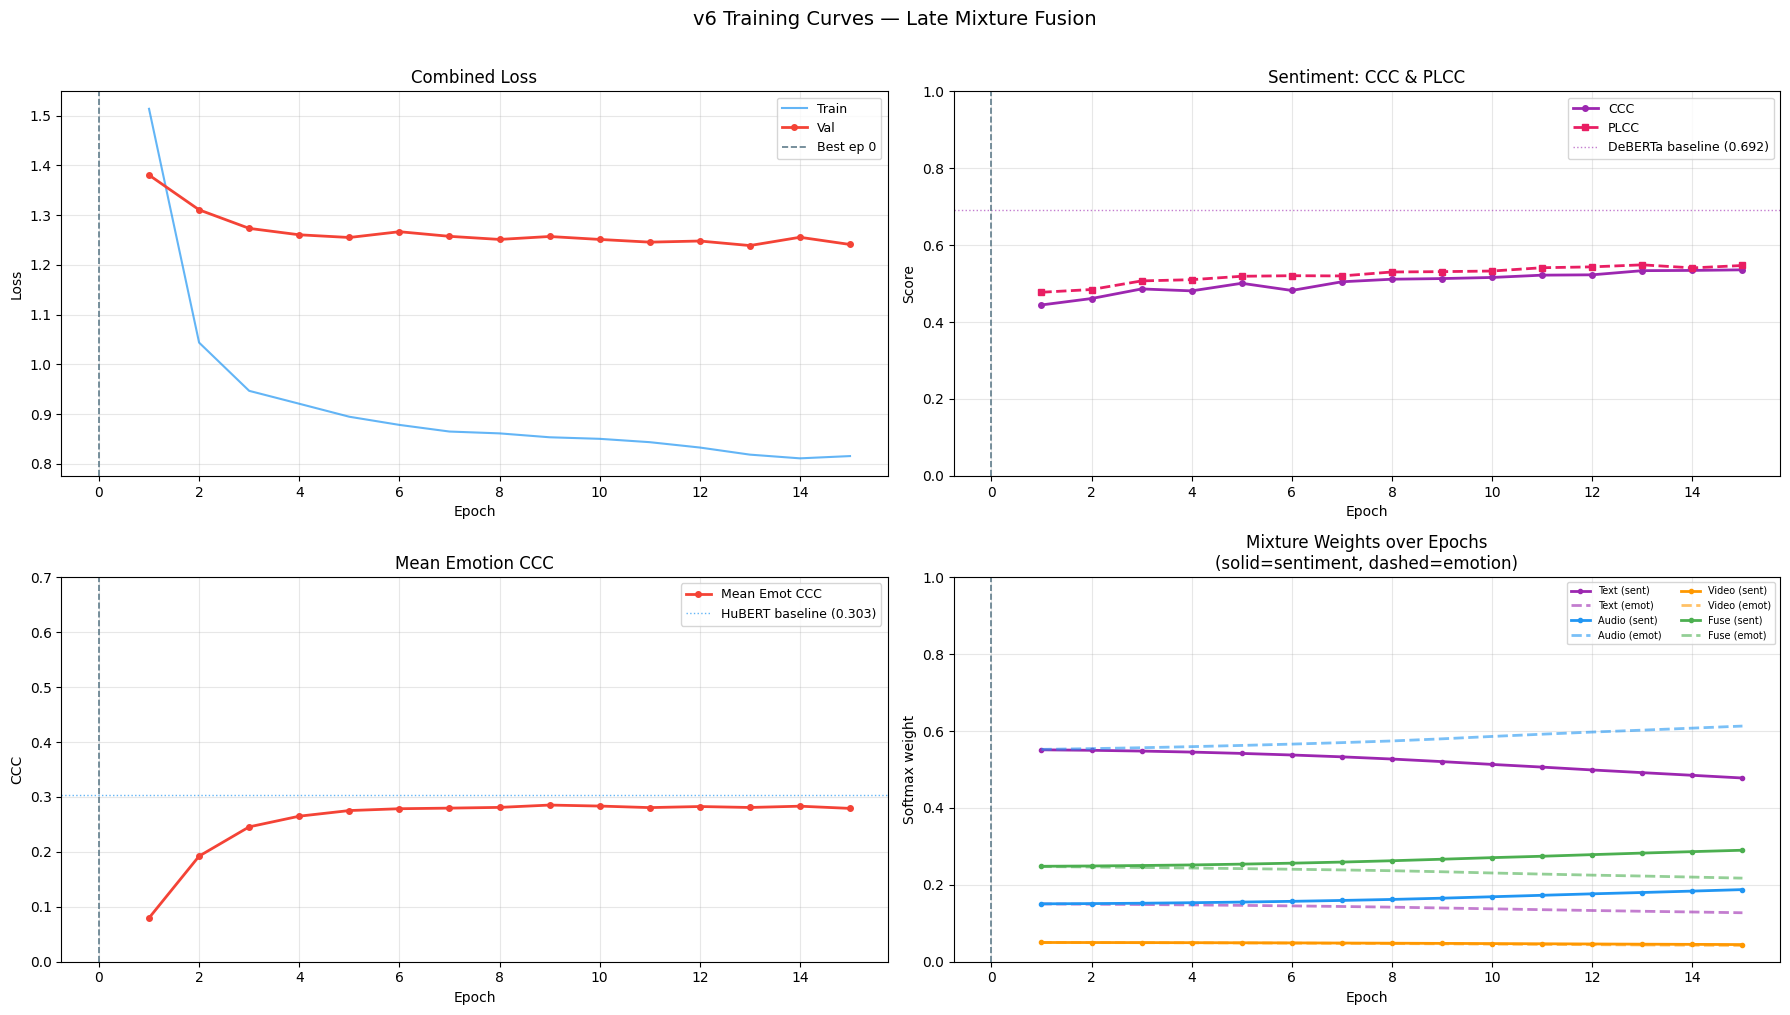

Saved → /content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v6/v6_training_curves.png


In [ ]:
# Training curves
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# Colour palette - consistent across all plots
C = {
    "text":     "#9C27B0",   # purple
    "audio":    "#2196F3",   # blue
    "video":    "#FF9800",   # orange
    "fuse":     "#4CAF50",   # green
    "combined": "#F44336",   # red
    "train":    "#2196F3",
    "val":      "#F44336",
    "best":     "#607D8B",   # grey dashed
}
MOD_LABELS = ["Text", "Audio", "Video", "Fuse"]

epochs_ran = range(1, len(history["train_loss"]) + 1)
w_sent_arr = np.array(history["w_sent"])   # (E, 4)
w_emot_arr = np.array(history["w_emot"])   # (E, 4)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle("v6 Training Curves - Late Mixture Fusion", fontsize=14, y=1.01)

# Panel 1: Loss
ax = axes[0, 0]
ax.plot(epochs_ran, history["train_loss"], label="Train", color=C["train"],
        linewidth=1.5, alpha=0.7)
ax.plot(epochs_ran, history["val_loss"],   label="Val",   color=C["val"],
        linewidth=2, marker="o", markersize=4)
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2,
           label=f"Best ep {best_epoch}")
ax.set_title("Combined Loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# Panel 2: Sentiment metrics
ax = axes[0, 1]
ax.plot(epochs_ran, history["sent_ccc"],  label="CCC",  color="#9C27B0",
        linewidth=2, marker="o", markersize=4)
ax.plot(epochs_ran, history["sent_plcc"], label="PLCC", color="#E91E63",
        linewidth=2, marker="s", markersize=4, linestyle="--")
ax.axhline(0.6918, color="#9C27B0", linestyle=":", linewidth=1, alpha=0.6,
           label="DeBERTa baseline (0.692)")
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax.set_title("Sentiment: CCC & PLCC")
ax.set_xlabel("Epoch"); ax.set_ylabel("Score"); ax.set_ylim(0.0, 1.0)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# Panel 3: Emotion CCC
ax = axes[1, 0]
ax.plot(epochs_ran, history["mean_emot_ccc"], label="Mean Emot CCC",
        color=C["combined"], linewidth=2, marker="o", markersize=4)
ax.axhline(0.3027, color=C["audio"], linestyle=":", linewidth=1, alpha=0.7,
           label="HuBERT baseline (0.303)")
ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax.set_title("Mean Emotion CCC")
ax.set_xlabel("Epoch"); ax.set_ylabel("CCC"); ax.set_ylim(0.0, 0.7)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# Panel 4: Mixture weight evolution
ax = axes[1, 1]
mod_colors = [C["text"], C["audio"], C["video"], C["fuse"]]
for i, (label, color) in enumerate(zip(MOD_LABELS, mod_colors)):
    ax.plot(epochs_ran, w_sent_arr[:, i], color=color, linewidth=2,
            label=f"{label} (sent)", linestyle="-", marker="o", markersize=3)
    ax.plot(epochs_ran, w_emot_arr[:, i], color=color, linewidth=2,
            label=f"{label} (emot)", linestyle="--", alpha=0.6)
ax.set_title("Mixture Weights over Epochs\n(solid=sentiment, dashed=emotion)")
ax.set_xlabel("Epoch"); ax.set_ylabel("Softmax weight")
ax.set_ylim(0, 1); ax.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/v6_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {OUTPUT_DIR}/v6_training_curves.png")


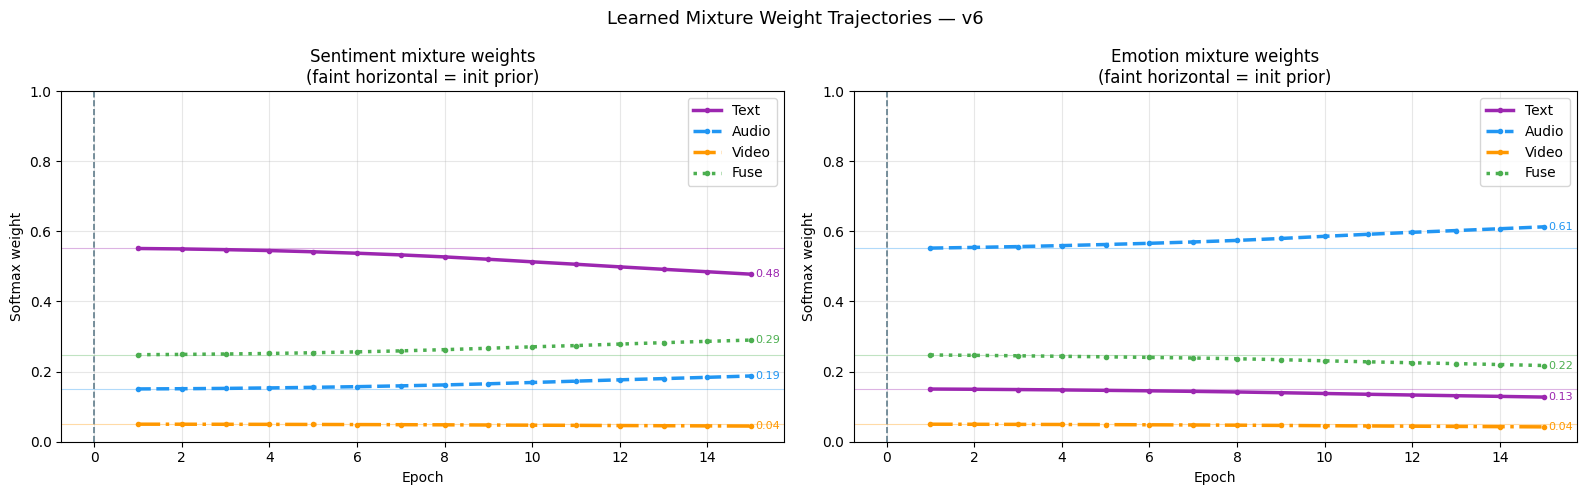

Saved → /content/drive/Shareddrives/AI Capstone/Middle Fusion/fusion-mosei-v6/v6_mixture_weights.png

Final mixture weights:
  Sentiment  [text, audio, video, fuse]: [0.478 0.188 0.045 0.29 ]
  Emotion    [text, audio, video, fuse]: [0.127 0.613 0.042 0.217]

  Video sentiment weight: 0.045 (started 0.050)
  Video emotion weight:   0.042 (started 0.050)
  → Video contributed little to sentiment — safe to drop in v7
  → Video contributed little to emotion   — safe to drop in v7


In [ ]:
# Mixture weight trajectories (detail)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Learned Mixture Weight Trajectories - v6", fontsize=13)

mod_colors  = [C["text"], C["audio"], C["video"], C["fuse"]]
mod_styles  = ["-", "--", "-.", ":"]

# Init weights for reference lines
import torch, torch.nn.functional as F
w_s_init = F.softmax(torch.tensor([0.0, -1.3, -2.4, -0.8]), dim=0).numpy()
w_e_init = F.softmax(torch.tensor([-1.3, 0.0, -2.4, -0.8]), dim=0).numpy()

for i, (label, color, ls) in enumerate(zip(MOD_LABELS, mod_colors, mod_styles)):
    ax1.plot(epochs_ran, w_sent_arr[:, i], color=color, linewidth=2.5,
             linestyle=ls, label=label, marker="o", markersize=3)
    ax1.axhline(w_s_init[i], color=color, linewidth=0.8, alpha=0.35, linestyle="-")

ax1.set_title("Sentiment mixture weights\n(faint horizontal = init prior)")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Softmax weight")
ax1.set_ylim(0, 1); ax1.legend(fontsize=10); ax1.grid(True, alpha=0.3)
ax1.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2, label=f"Best ep {best_epoch}")
ax1.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

for i, (label, color, ls) in enumerate(zip(MOD_LABELS, mod_colors, mod_styles)):
    ax2.plot(epochs_ran, w_emot_arr[:, i], color=color, linewidth=2.5,
             linestyle=ls, label=label, marker="o", markersize=3)
    ax2.axhline(w_e_init[i], color=color, linewidth=0.8, alpha=0.35, linestyle="-")

ax2.set_title("Emotion mixture weights\n(faint horizontal = init prior)")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Softmax weight")
ax2.set_ylim(0, 1); ax2.legend(fontsize=10); ax2.grid(True, alpha=0.3)
ax2.axvline(best_epoch, color=C["best"], linestyle="--", linewidth=1.2)
ax2.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# Annotate final weights
final_w_s = w_sent_arr[-1]
final_w_e = w_emot_arr[-1]
for i, (label, color) in enumerate(zip(MOD_LABELS, mod_colors)):
    ax1.annotate(f"{final_w_s[i]:.2f}", xy=(len(epochs_ran), final_w_s[i]),
                 xytext=(3, 0), textcoords="offset points",
                 fontsize=8, color=color, va="center")
    ax2.annotate(f"{final_w_e[i]:.2f}", xy=(len(epochs_ran), final_w_e[i]),
                 xytext=(3, 0), textcoords="offset points",
                 fontsize=8, color=color, va="center")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/v6_mixture_weights.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {OUTPUT_DIR}/v6_mixture_weights.png")

# Print summary
print("\nFinal mixture weights:")
print(f"  Sentiment  [text, audio, video, fuse]: {final_w_s.round(3)}")
print(f"  Emotion    [text, audio, video, fuse]: {final_w_e.round(3)}")
print(f"\n  Video sentiment weight: {final_w_s[2]:.3f} (started {w_s_init[2]:.3f})")
print(f"  Video emotion weight:   {final_w_e[2]:.3f} (started {w_e_init[2]:.3f})")
if final_w_s[2] < 0.08:
    print("  → Video contributed little to sentiment - safe to drop in v7")
if final_w_e[2] < 0.08:
    print("  → Video contributed little to emotion   - safe to drop in v7")
